# ORN Multimodal Baselines & Visual Research Notebook

**Purpose:** interlink the supplied ORN clinical/dosimetric cohort with the published ORN-specific CT-radiomics resource, add richer visual diagnostics, run reproducible tabular baselines, and provide guarded entry points for radiomics / CT deep-learning experiments.

**Important scientific boundary:** the supplied cohort (`TTE_ORN_data_Figshare.csv`) has 1,129 patients with clinical and DVH variables. The ORN-specific CT radiomics Figshare landing page is currently marked **“This item is shared privately”** when checked, despite the article describing data availability.

## Research links
- ORN-specific CT radiomics paper (150 patients; 1,316 features extracted from ORN/control mandibular ROIs): https://pmc.ncbi.nlm.nih.gov/articles/PMC12276996/
- Its Figshare share link (currently private/unavailable to anonymous access in the web check): https://figshare.com/s/728333f8ea94e555e77a
- ORN time-to-event clinical/dosimetric data DOI: https://doi.org/10.6084/m9.figshare.26240435.v1
- Published code / survival model: https://github.com/LaiaHV-MDACC/ORN-time-to-event-prediction-modelling

## 1. Setup and configuration

In [1]:
import os, sys, io, gzip, base64, json, warnings, textwrap, urllib.request, urllib.error
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

# Change these paths after downloading/accessing the ORN radiomics data.
RADIOMICS_TABLE_PATH = Path("data/orn_radiomics_features.csv")
# For deep-learning data, use a CSV manifest with one row per image/crop and a patient ID.
CT_CROP_MANIFEST_PATH = Path("data/orn_ct_crop_manifest.csv")
# For serial imaging, use one row per patient with explicit T0..T4 feature-vector file paths,
# or a long table with patient_id, timepoint, label, and numeric radiomics columns.
SERIAL_RAD_FEATURES_PATH = Path("data/orn_serial_T0_T4_features.csv")

print("Python:", sys.version.split()[0])
print("Working directory:", Path.cwd())
try:
    import xgboost
    print("XGBoost:", xgboost.__version__)
except Exception as e:
    print("XGBoost unavailable; notebook will use Random Forest and fallback sklearn model.", repr(e))
try:
    import torch
    print("PyTorch:", torch.__version__)
except Exception as e:
    print("PyTorch unavailable; ResNet/LSTM sections will remain optional.", repr(e))

Python: 3.13.5
Working directory: /mnt/data


XGBoost: 3.1.3


PyTorch: 2.10.0+cpu


## 2. Load the supplied real ORN clinical/DVH cohort

In [2]:
# Embedded compressed copy of the supplied CSV makes this notebook portable.
_CSV_GZIP_B64 = """..."""
raw = gzip.decompress(base64.b64decode(_CSV_GZIP_B64))
df = pd.read_csv(io.BytesIO(raw))
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_n": df.isna().sum(), "missing_pct": (df.isna().mean()*100).round(2)}).sort_values("missing_pct", ascending=False).head(15))

Dataset shape: 1,129 rows × 61 columns


,Study ID,Gender,Age,Overall survival,Overall survival time,ORN status,Time to event,ORN Grade (Tsai),Smoking status,Smoking Pack-Years,Pre-RT dental extractions,T Stage,N Stage,Chemotherapy,Postop RT vs. Definitive RT,HPV/P16 +Ve,Tumor site group,Mandible volume (cc),V5Gy,V10Gy,V15Gy,V20Gy,V25Gy,V30Gy,V35Gy,V40Gy,V45Gy,V50Gy,V55Gy,V60Gy,V65Gy,V70Gy,V75Gy,V80Gy,D0.5%,D1%,D2%,D3%,D5%,D10%,D15%,D20%,D25%,D30%,D35%,D40%,D45%,D50%,D55%,D60%,D65%,D70%,D75%,D80%,D85%,D90%,D95%,D97%,D98%,D99%,D99.5%
0,2,Male,58,0,117.0,0,117.40,0,Never,0.0,0,T4,N0,No Chemotherapy,postop_RT,Unknown,Oral Cavity,113.43,100.00,90.98,81.84,67.84,62.39,54.82,47.61,41.89,38.04,35.21,31.04,5.31,0.00,0.0,0.0,0.0,62.35,62.07,61.63,61.18,60.13,59.04,58.66,58.27,57.80,55.91,50.24,41.92,36.84,33.13,29.90,27.06,22.44,18.73,17.27,15.90,12.85,10.42,8.29,7.52,7.02,6.53,6.30
1,4,Male,58,1,45.6,0,45.40,0,Never,0.0,1,T2,N0,Concurrent Chemotherapy,postop_RT,Unknown,Oral Cavity,84.56,98.34,92.20,89.98,87.53,86.29,84.76,83.01,79.73,70.22,55.45,31.49,5.86,0.00,0.0,0.0,0.0,62.74,61.96,61.37,60.89,60.20,59.01,57.97,57.09,56.14,55.22,54.52,53.62,52.52,51.18,50.10,48.65,47.08,45.09,42.90,39.74,29.65,14.91,7.18,5.93,5.23,3.72,2.59
2,8,Male,82,1,134.2,0,117.50,0,Former,70.0,0,T2,N1,No Chemotherapy,postop_RT,Unknown,Oral Cavity,88.24,99.79,97.77,93.73,92.05,90.33,86.89,83.80,78.34,70.26,56.73,35.93,7.95,0.00,0.0,0.0,0.0,61.53,61.26,60.96,60.79,60.47,59.66,58.72,57.54,56.78,55.97,55.20,54.14,52.83,51.76,50.45,49.09,47.27,45.12,42.07,39.17,33.16,25.49,12.51,10.62,9.80,8.18,6.42
3,9,Male,70,1,46.2,0,46.00,0,Former,35.0,0,T1,N2A,No Chemotherapy,Definitive,Unknown,Oropharynx,62.10,97.51,90.61,85.16,82.55,78.90,66.20,50.49,36.75,30.20,27.19,23.30,15.59,4.58,0.0,0.0,0.0,66.88,66.56,66.17,65.75,64.78,62.69,60.40,57.03,53.48,45.19,41.00,38.20,36.36,35.12,33.98,32.34,30.28,28.64,26.87,23.97,15.33,10.40,7.00,5.57,4.60,3.67,3.03
4,15,Female,66,0,86.0,1,5.45,4,Never,0.0,1,T1,N0,Concurrent Chemotherapy,postop_RT,Unknown,Oral Cavity,65.90,83.99,80.40,77.94,76.89,75.73,74.77,73.61,72.65,70.81,68.69,60.77,34.69,1.02,0.0,0.0,0.0,66.44,65.04,63.75,63.35,62.91,62.26,61.71,61.33,60.96,60.53,59.97,59.25,58.30,57.56,56.76,55.22,53.48,48.14,28.28,10.60,4.31,2.01,1.19,0.98,0.88,0.81,0.78


,dtype,missing_n,missing_pct
Study ID,int64,0,0.0
Gender,object,0,0.0
Age,int64,0,0.0
Overall survival,int64,0,0.0
Overall survival time,float64,0,0.0
ORN status,int64,0,0.0
Time to event,float64,0,0.0
ORN Grade (Tsai),int64,0,0.0
Smoking status,object,0,0.0
Smoking Pack-Years,float64,0,0.0


## 3. Cohort overview: ORN prevalence, grade, follow-up, and age

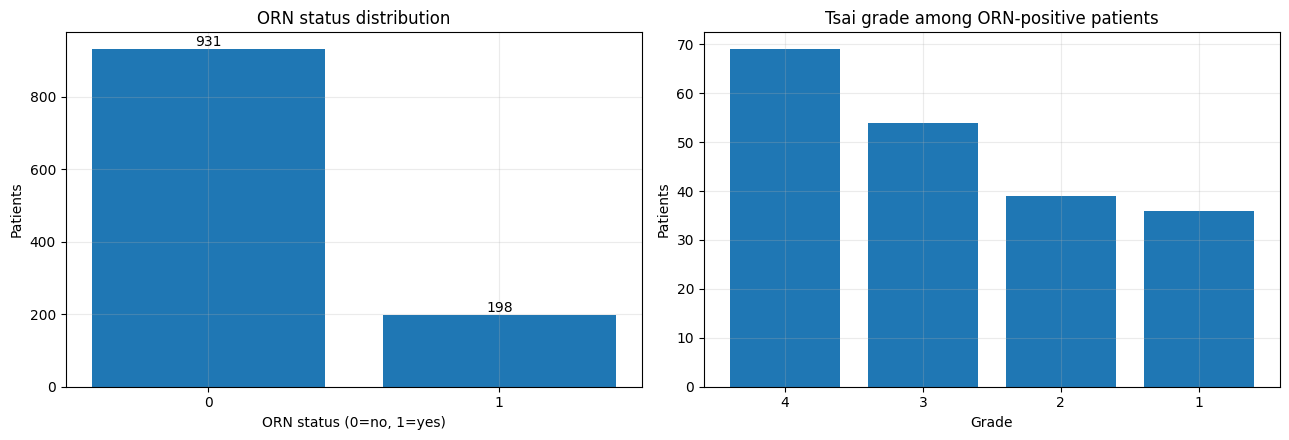

ORN positive: 198 / 1129 labelled patients (17.5% of rows)


,count,mean,std,min,25%,50%,75%,max
ORN status,,,,,,,,
0,931.0,60.57,10.27,23.0,54.0,60.0,68.0,89.0
1,198.0,59.85,8.74,34.0,54.0,60.0,66.0,80.0


,count,mean,std,min,25%,50%,75%,max
ORN status,,,,,,,,
0,931.0,75.26,43.81,1.50,42.10,71.70,104.80,210.50
1,198.0,33.89,36.13,2.03,9.98,20.53,45.03,194.23


In [3]:
target_col = "ORN status"
if target_col not in df.columns:
    raise ValueError("Expected ORN status target was not found in the supplied dataset.")
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
counts = df[target_col].value_counts(dropna=False).sort_index()
ax[0].bar([str(x) for x in counts.index], counts.values)
ax[0].set_title("ORN status distribution")
ax[0].set_xlabel("ORN status (0=no, 1=yes)"); ax[0].set_ylabel("Patients")
for i,v in enumerate(counts.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
if "ORN Grade (Tsai)" in df:
    g = df.loc[df[target_col] == 1, "ORN Grade (Tsai)"].fillna("Unknown").astype(str).value_counts()
    ax[1].bar(g.index, g.values)
    ax[1].set_title("Tsai grade among ORN-positive patients")
    ax[1].set_xlabel("Grade"); ax[1].set_ylabel("Patients")
else:
    ax[1].axis("off")
plt.tight_layout(); plt.show()
print(f"ORN positive: {(df[target_col] == 1).sum()} / {df[target_col].notna().sum()} labelled patients ({100*(df[target_col] == 1).mean():.1f}% of rows)")
if "Age" in df:
    display(df.groupby(target_col)["Age"].describe().round(2))
if "Time to event" in df:
    display(df.groupby(target_col)["Time to event"].describe().round(2))

## 4. Visual EDA: missingness, age, tumour site, smoking, and dose-volume features

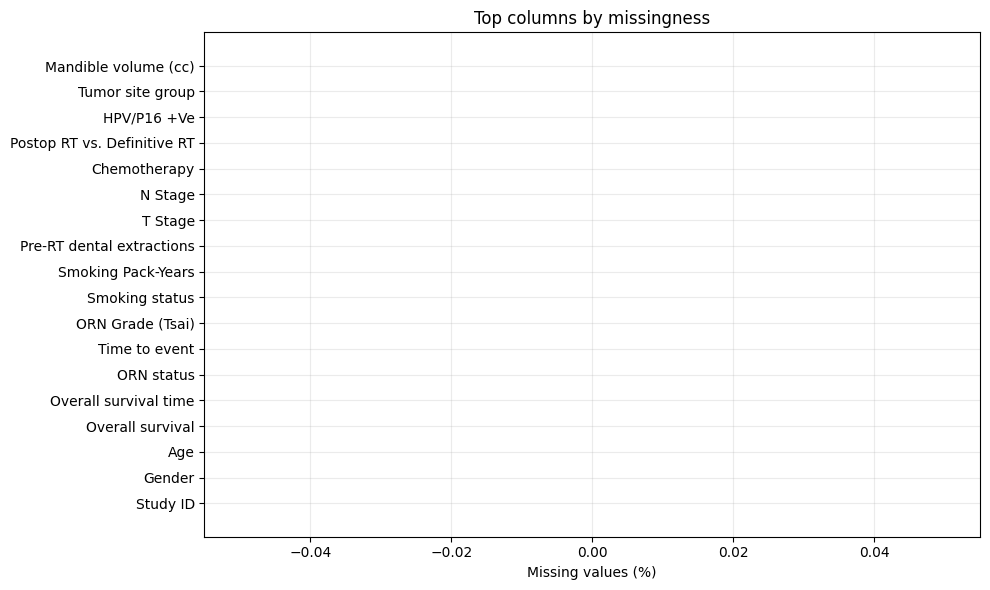

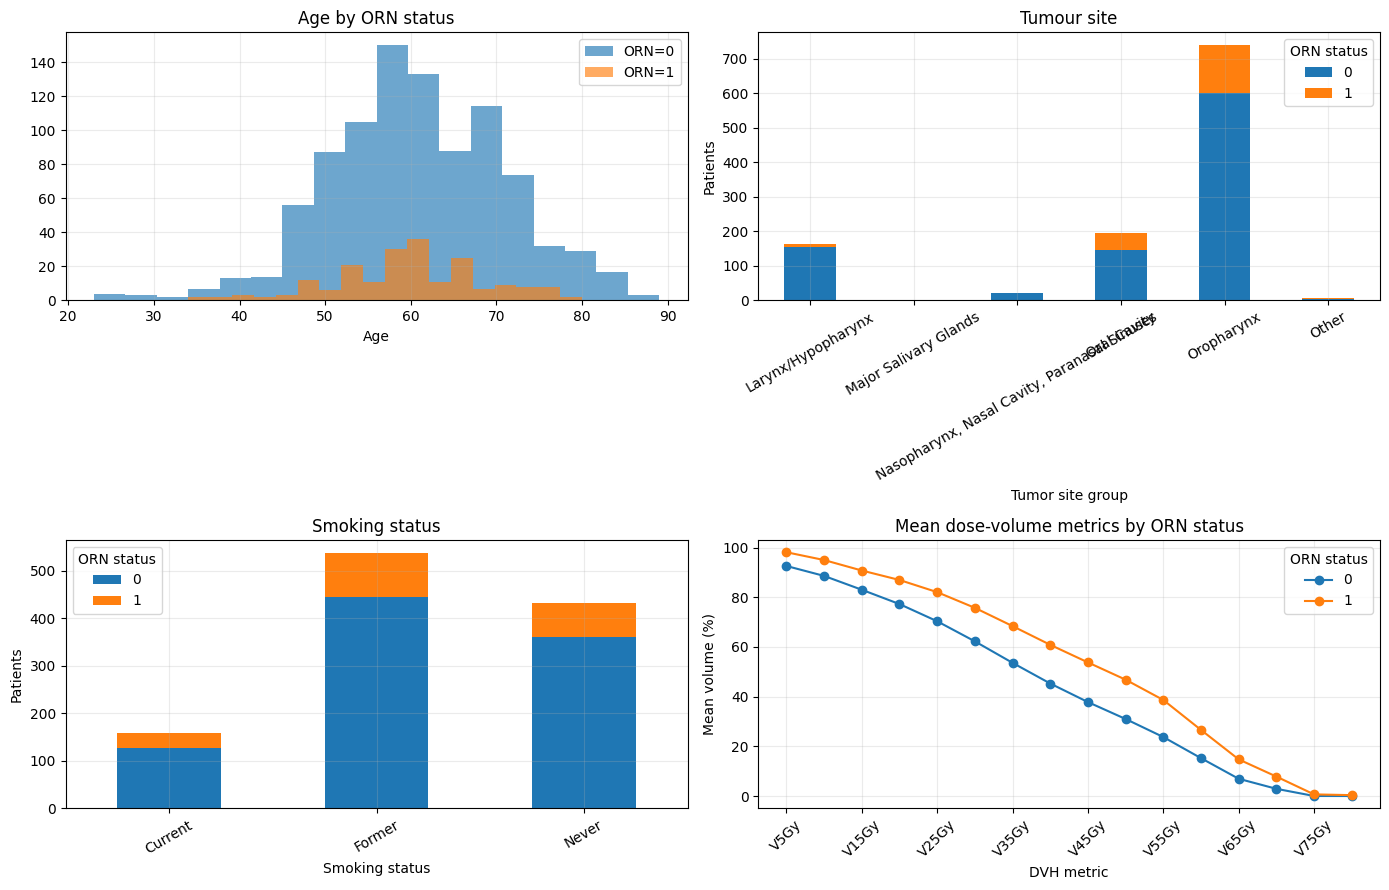

In [4]:
# Missingness plot for columns with the most missing values
miss = (df.isna().mean()*100).sort_values(ascending=False).head(18).sort_values()
plt.figure(figsize=(10,6)); plt.barh(miss.index.astype(str), miss.values)
plt.xlabel("Missing values (%)"); plt.title("Top columns by missingness"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
if "Age" in df:
    for y, sub in df.groupby(target_col): axes[0,0].hist(pd.to_numeric(sub["Age"], errors="coerce").dropna(), bins=18, alpha=.65, label=f"ORN={int(y)}")
    axes[0,0].set_title("Age by ORN status"); axes[0,0].set_xlabel("Age"); axes[0,0].legend()
for col, axx, title in [("Tumor site group", axes[0,1], "Tumour site"), ("Smoking status", axes[1,0], "Smoking status")]:
    if col in df:
        tab = pd.crosstab(df[col].fillna("Unknown"), df[target_col])
        tab.plot(kind="bar", stacked=True, ax=axx)
        axx.set_title(title); axx.set_ylabel("Patients"); axx.tick_params(axis="x", rotation=30)
        axx.legend(title="ORN status")
dvh_cols = [c for c in df.columns if c.startswith("V") and c.endswith("Gy")]
if dvh_cols:
    means = df.groupby(target_col)[dvh_cols].mean().T
    means.plot(ax=axes[1,1], marker="o")
    axes[1,1].set_title("Mean dose-volume metrics by ORN status")
    axes[1,1].set_xlabel("DVH metric"); axes[1,1].set_ylabel("Mean volume (%)")
    axes[1,1].tick_params(axis="x", rotation=45); axes[1,1].legend(title="ORN status")
plt.tight_layout(); plt.show()

## 5. Correlation heatmap for selected numeric features

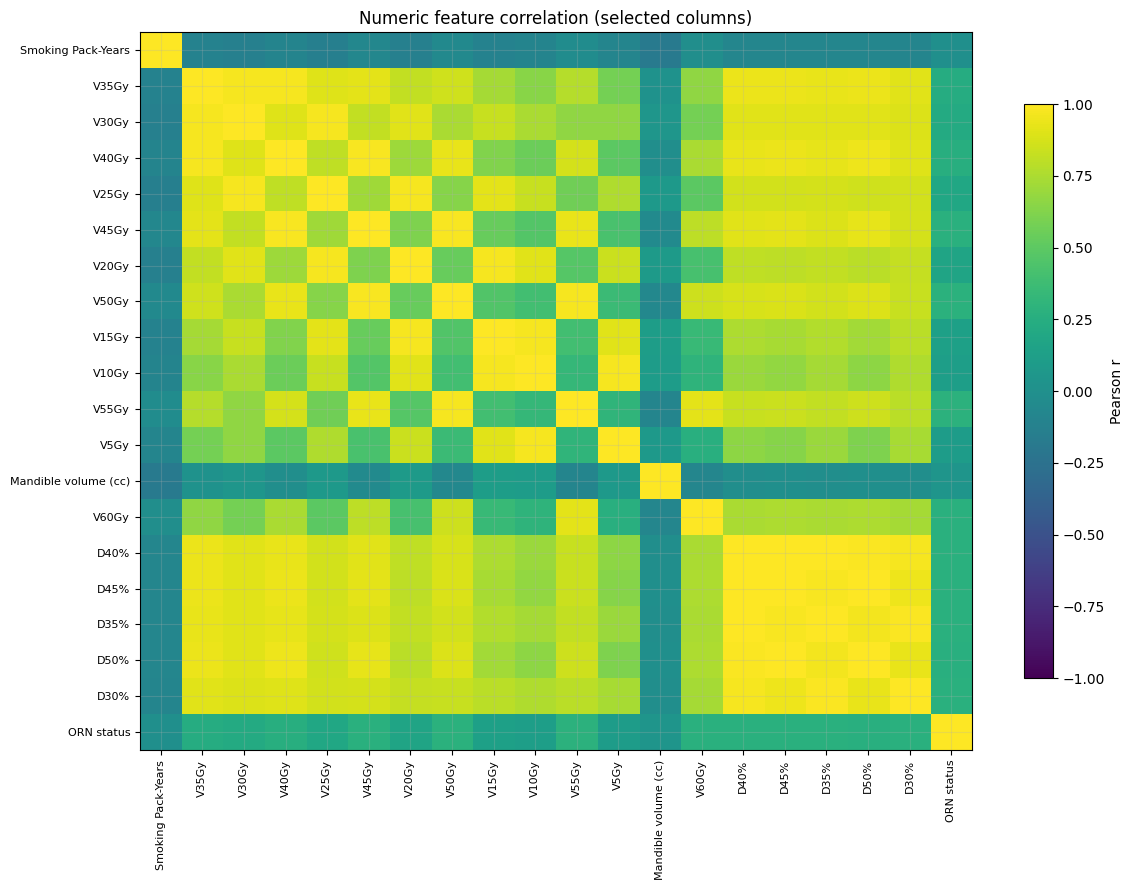

In [5]:
numeric = df.select_dtypes(include=np.number).copy()
exclude_corr = [c for c in ["Study ID", "Overall survival time", "Time to event", "ORN Grade (Tsai)"] if c in numeric]
num_for_corr = numeric.drop(columns=exclude_corr, errors="ignore")
# Pick most variable numeric columns to keep the heatmap readable.
cols = num_for_corr.var(numeric_only=True).sort_values(ascending=False).head(20).index.tolist()
if target_col in num_for_corr and target_col not in cols: cols = cols[:19] + [target_col]
corr = num_for_corr[cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 9)); im = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
ax.set_title("Numeric feature correlation (selected columns)"); fig.colorbar(im, ax=ax, shrink=.8, label="Pearson r")
plt.tight_layout(); plt.show()

## 6. Define leakage-aware tabular modelling task

In [6]:
# Target is the cohort's observed ORN status. Do not include downstream outcomes or identifiers.
leakage_cols = ["Study ID", "ORN status", "ORN Grade (Tsai)", "Time to event", "Overall survival", "Overall survival time"]
feature_df = df.drop(columns=[c for c in leakage_cols if c in df.columns]).copy()
y = pd.to_numeric(df[target_col], errors="coerce")
valid = y.notna()
X = feature_df.loc[valid].copy()
y = y.loc[valid].astype(int)
# Exclude columns that are entirely missing and constant.
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=False) > 1]
print("Rows used:", len(X), "positive:", int(y.sum()), "negative:", int((y==0).sum()))
print("Feature columns:", X.shape[1])
print("Excluded to avoid direct leakage/identification:", [c for c in leakage_cols if c in df.columns])
print("Caution: retrospective observed-status classification is not equivalent to prospective time-to-ORN prediction or PREDMORN NTCP validation.")

Rows used: 1129 positive: 198 negative: 931
Feature columns: 55
Excluded to avoid direct leakage/identification: ['Study ID', 'ORN status', 'ORN Grade (Tsai)', 'Time to event', 'Overall survival', 'Overall survival time']
Caution: retrospective observed-status classification is not equivalent to prospective time-to-ORN prediction or PREDMORN NTCP validation.


## 7. Train/test split and model pipelines

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, brier_score_loss, log_loss,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
cat_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", ohe)]), cat_cols)
], remainder="drop")
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows | Numeric features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

Train: 903 rows | Test: 226 rows | Numeric features: 47 | Categorical features: 8


## 8. Fit Random Forest and XGBoost (with safe fallback)

In [8]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}
try:
    from xgboost import XGBClassifier
    scale_pos_weight = max(1, (y_train == 0).sum() / max(1, (y_train == 1).sum()))
    models["XGBoost"] = XGBClassifier(n_estimators=350, max_depth=3, learning_rate=0.035,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=2.0, min_child_weight=3,
        objective="binary:logistic", eval_metric="logloss", scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE, n_jobs=4)
except Exception as e:
    print("XGBoost import failed; using HistGradientBoosting as a clearly labelled fallback:", repr(e))
    models["HistGradientBoosting (fallback)"] = HistGradientBoostingClassifier(max_iter=200, random_state=RANDOM_STATE)

fitted = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    print("Fitted:", name)
print("All models fitted on the supplied real clinical/DVH cohort.")

Fitted: Random Forest


Fitted: XGBoost
All models fitted on the supplied real clinical/DVH cohort.


## 9. Quantitative evaluation: AUC, F1, calibration, and threshold metrics

,ROC-AUC,PR-AUC/AP,F1,Precision,Recall/Sensitivity,Accuracy,Brier score (lower better),Log loss (lower better)
Model,,,,,,,,
XGBoost,0.6406,0.2900,0.3256,0.3043,0.35,0.7434,0.1782,0.5418
Random Forest,0.6371,0.2918,0.2182,0.4000,0.15,0.8097,0.1491,0.4851


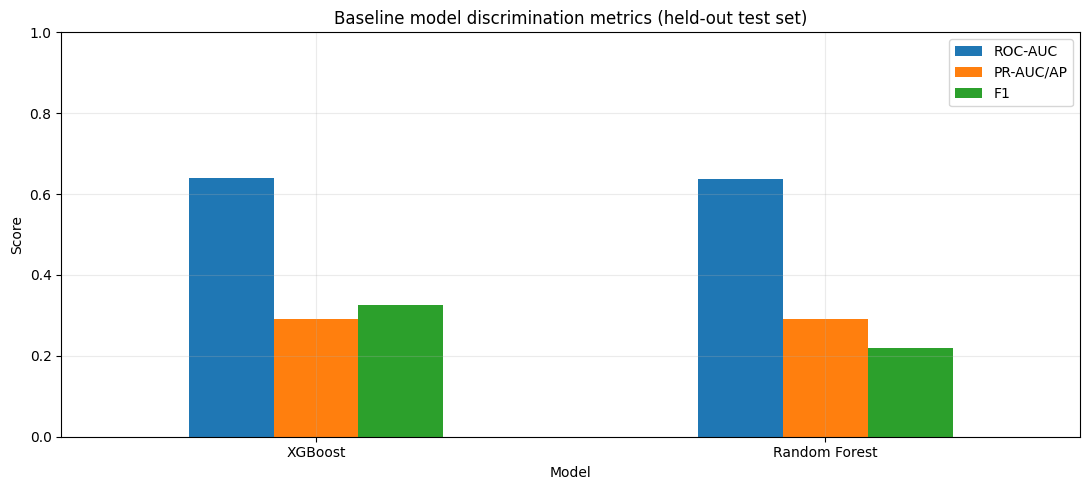

In [9]:
results, probs = [], {}
for name, model in fitted.items():
    p = model.predict_proba(X_test)[:,1]
    pred = (p >= 0.5).astype(int)
    probs[name] = p
    results.append({"Model": name, "ROC-AUC": roc_auc_score(y_test,p), "PR-AUC/AP": average_precision_score(y_test,p),
                    "F1": f1_score(y_test,pred, zero_division=0), "Precision": precision_score(y_test,pred, zero_division=0),
                    "Recall/Sensitivity": recall_score(y_test,pred, zero_division=0), "Accuracy": accuracy_score(y_test,pred),
                    "Brier score (lower better)": brier_score_loss(y_test,p), "Log loss (lower better)": log_loss(y_test,p, labels=[0,1])})
metrics = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(metrics.round(4))
ax = metrics[["ROC-AUC", "PR-AUC/AP", "F1"]].plot(kind="bar", figsize=(11,5), ylim=(0,1), rot=0)
ax.set_title("Baseline model discrimination metrics (held-out test set)"); ax.set_ylabel("Score"); plt.tight_layout(); plt.show()

## 10. ROC and precision–recall curves

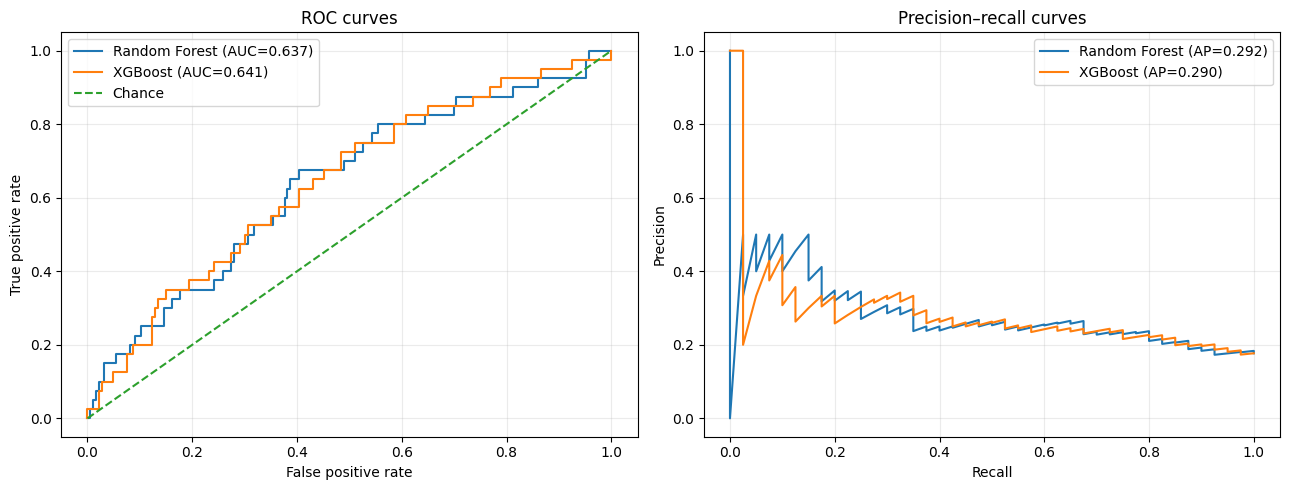

In [10]:
fig, ax = plt.subplots(1,2,figsize=(13,5))
for name,p in probs.items():
    fpr,tpr,_ = roc_curve(y_test,p); ax[0].plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
    prec,rec,_ = precision_recall_curve(y_test,p); ax[1].plot(rec,prec,label=f"{name} (AP={average_precision_score(y_test,p):.3f})")
ax[0].plot([0,1],[0,1],"--",label="Chance"); ax[0].set(xlabel="False positive rate",ylabel="True positive rate",title="ROC curves"); ax[0].legend()
ax[1].set(xlabel="Recall",ylabel="Precision",title="Precision–recall curves"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Calibration plots and confusion matrices

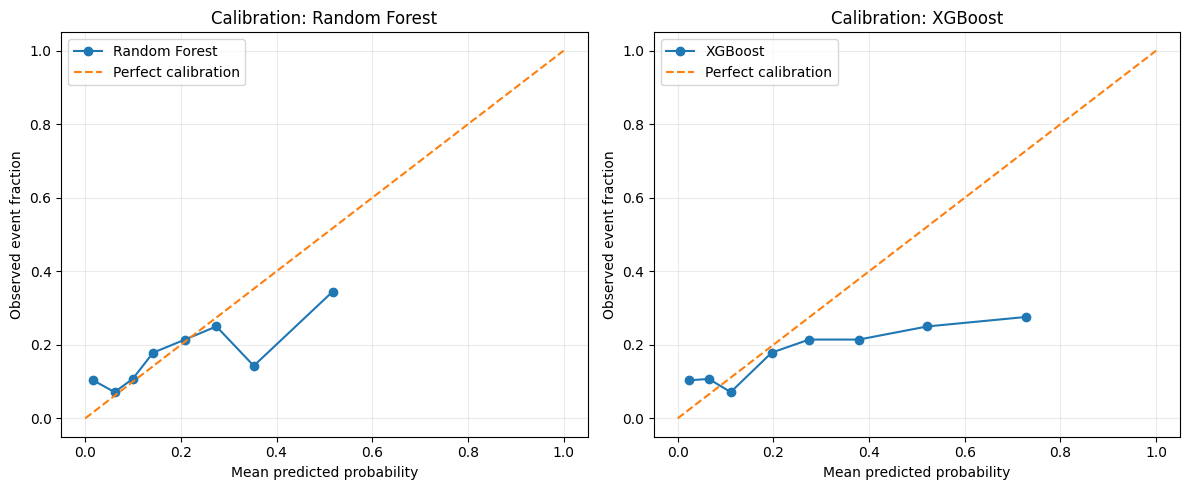

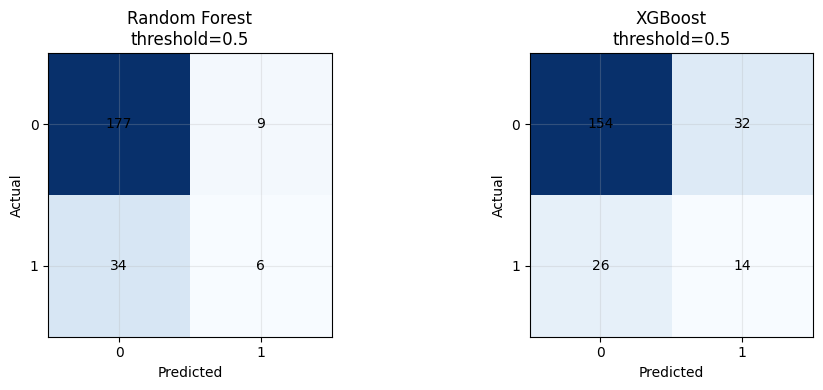

In [11]:
fig, ax = plt.subplots(1, len(probs), figsize=(6*len(probs),5), squeeze=False)
for i,(name,p) in enumerate(probs.items()):
    frac, meanp = calibration_curve(y_test,p,n_bins=8,strategy="quantile")
    ax[0,i].plot(meanp,frac,marker="o",label=name); ax[0,i].plot([0,1],[0,1],"--",label="Perfect calibration")
    ax[0,i].set(xlabel="Mean predicted probability",ylabel="Observed event fraction",title=f"Calibration: {name}"); ax[0,i].legend()
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1,len(probs),figsize=(5*len(probs),4),squeeze=False)
for i,(name,p) in enumerate(probs.items()):
    cm=confusion_matrix(y_test,(p>=0.5).astype(int),labels=[0,1])
    axes[0,i].imshow(cm, cmap="Blues")
    axes[0,i].set_title(name+"\nthreshold=0.5"); axes[0,i].set_xlabel("Predicted"); axes[0,i].set_ylabel("Actual")
    axes[0,i].set_xticks([0,1]); axes[0,i].set_yticks([0,1])
    for (r,c),v in np.ndenumerate(cm): axes[0,i].text(c,r,str(v),ha="center",va="center")
plt.tight_layout(); plt.show()

## 12. Feature importance visualizations

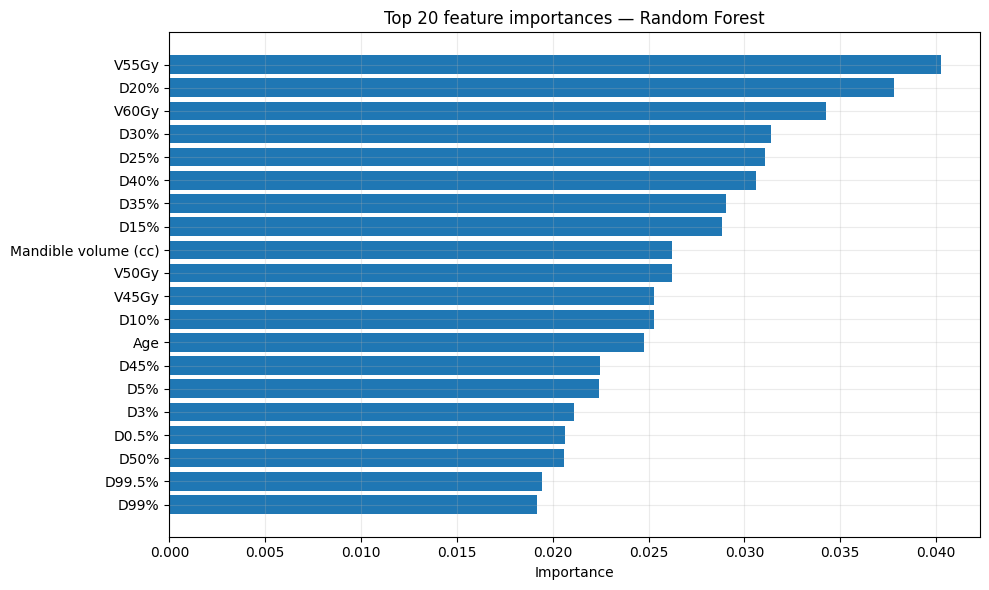

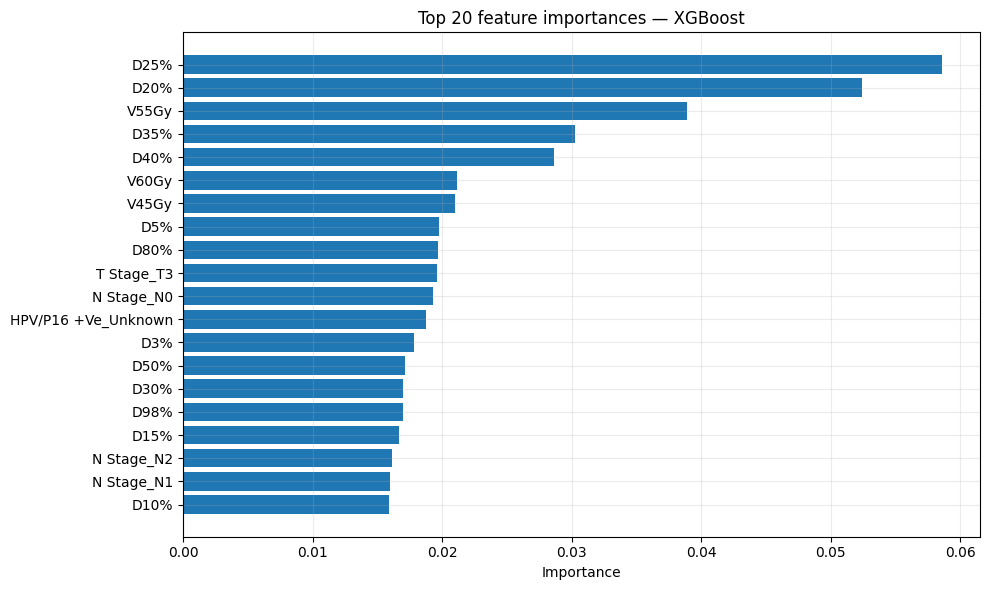

In [12]:
def transformed_feature_names(prep):
    names=[]
    if num_cols: names.extend(num_cols)
    if cat_cols:
        try: names.extend(prep.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(cat_cols).tolist())
        except Exception: names.extend([f"categorical_feature_{i}" for i in range(prep.named_transformers_["cat"].transform(X_train.iloc[:2]).shape[1])])
    return names
for name, pipe in fitted.items():
    model=pipe.named_steps["model"]
    if hasattr(model,"feature_importances_"):
        fn=transformed_feature_names(pipe.named_steps["prep"])
        vals=np.asarray(model.feature_importances_)
        if len(fn)!=len(vals): fn=[f"feature_{i}" for i in range(len(vals))]
        imp=pd.Series(vals,index=fn).sort_values(ascending=False).head(20).sort_values()
        plt.figure(figsize=(10,6)); plt.barh(imp.index,imp.values)
        plt.title(f"Top 20 feature importances — {name}"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()
    else:
        print(name, "does not expose built-in feature importance.")

## 17. Published benchmark: ORN radiomics and PREDMORN/NTCP context

,Model / study,AUC,Accuracy,Sensitivity,Specificity,Endpoint,Source
0,Published CT radiomics RF (cross-sectional ROI...,0.96,0.88,0.93,0.83,ORN ROI vs contralateral control ROI,https://pmc.ncbi.nlm.nih.gov/articles/PMC12276...
1,Published PREDMORN external validation (popula...,0.65,NaN,NaN,NaN,Patient-level ORN risk / NTCP prediction; dist...,https://pubmed.ncbi.nlm.nih.gov/40222595/


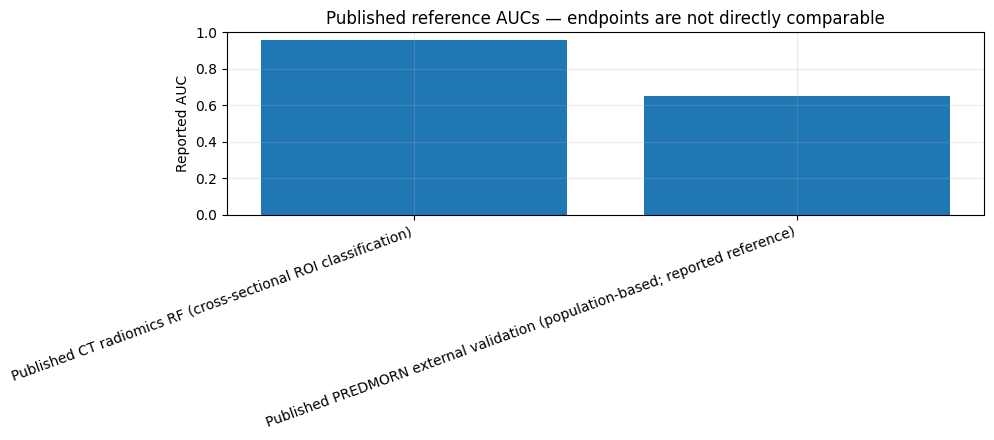

Do not rank these AUCs as a fair model comparison: the first is cross-sectional ROI discrimination; the second is patient-level risk prediction.


In [17]:
# Values below are literature-reported reference values, not results from this notebook.
# The ORN cross-sectional radiomics paper reports a 150-patient cohort, 1,316 extracted features,
# 67 selected features, test AUC 0.96, accuracy 0.88, sensitivity 0.93, specificity 0.83,
# log loss 0.296 and ECE 0.125 for ORN ROI vs contralateral control ROI.
# Published PREDMORN/NTCP-style clinical prediction metrics refer to different tasks/cohorts.
# They must not be presented as direct head-to-head comparators without matching endpoints and validation design.
bench = pd.DataFrame([
 {"Model / study":"Published CT radiomics RF (cross-sectional ROI classification)","AUC":0.96,"Accuracy":0.88,"Sensitivity":0.93,"Specificity":0.83,"Endpoint":"ORN ROI vs contralateral control ROI","Source":"https://pmc.ncbi.nlm.nih.gov/articles/PMC12276996/"},
 {"Model / study":"Published PREDMORN external validation (population-based; reported reference)","AUC":0.65,"Accuracy":np.nan,"Sensitivity":np.nan,"Specificity":np.nan,"Endpoint":"Patient-level ORN risk / NTCP prediction; distinct endpoint","Source":"https://pubmed.ncbi.nlm.nih.gov/40222595/"},
])
display(bench)
plt.figure(figsize=(10,4.5)); plt.bar(bench["Model / study"], bench["AUC"])
plt.ylim(0,1); plt.ylabel("Reported AUC"); plt.title("Published reference AUCs — endpoints are not directly comparable")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()
print("Do not rank these AUCs as a fair model comparison: the first is cross-sectional ROI discrimination; the second is patient-level risk prediction.")

## 19. Data access and reproducibility checklist

In [19]:
checklist = pd.DataFrame([
 ("Supplied clinical/DVH cohort loaded", True, "1,129 rows; embedded from the user-provided CSV"),
 ("Random Forest baseline trained", "Random Forest" in fitted, "Clinical/DVH predictors; observed ORN status"),
 ("XGBoost baseline trained", "XGBoost" in fitted, "Clinical/DVH predictors; observed ORN status"),
 ("ORN-specific radiomics table available", RADIOMICS_TABLE_PATH.exists(), str(RADIOMICS_TABLE_PATH)),
 ("Patient-linked T0–T4 feature table available", SERIAL_RAD_FEATURES_PATH.exists(), str(SERIAL_RAD_FEATURES_PATH)),
 ("Real CT crop manifest available", CT_CROP_MANIFEST_PATH.exists(), str(CT_CROP_MANIFEST_PATH)),
], columns=["Requirement","Available / completed","Notes"])
display(checklist)
print("Before publication: use patient-level splits, nested CV for feature selection, bootstrap confidence intervals, calibration slope/intercept, decision-curve analysis where appropriate, and external validation.")
print("Do not merge cohorts by guessed identifiers. Obtain explicit data-use permission and inspect data dictionaries/licences.")

,Requirement,Available / completed,Notes
0,Supplied clinical/DVH cohort loaded,True,"1,129 rows; embedded from the user-provided CSV"
1,Random Forest baseline trained,True,Clinical/DVH predictors; observed ORN status
2,XGBoost baseline trained,True,Clinical/DVH predictors; observed ORN status
3,ORN-specific radiomics table available,False,data/orn_radiomics_features.csv
4,Patient-linked T0–T4 feature table available,False,data/orn_serial_T0_T4_features.csv
5,Real CT crop manifest available,False,data/orn_ct_crop_manifest.csv


Before publication: use patient-level splits, nested CV for feature selection, bootstrap confidence intervals, calibration slope/intercept, decision-curve analysis where appropriate, and external validation.
Do not merge cohorts by guessed identifiers. Obtain explicit data-use permission and inspect data dictionaries/licences.


## Interpretation and next steps

1. The executed Random Forest and XGBoost results are **clinical/DVH-only retrospective baselines** using the supplied cohort. 
2. The ORN-specific CT radiomics paper is the most relevant public lead, but its Figshare share page currently reports private sharing.

### Sources
- Serageldin et al., *Computed tomography radiomics-based cross-sectional detection of mandibular osteoradionecrosis in head and neck cancer survivors* (2025): https://pmc.ncbi.nlm.nih.gov/articles/PMC12276996/
- Figshare radiomics resource: https://figshare.com/s/728333f8ea94e555e77a
- Humbert-Vidan et al., ORNJ time-to-event model/data: https://github.com/LaiaHV-MDACC/ORN-time-to-event-prediction-modelling
- Dataset DOI: https://doi.org/10.6084/m9.figshare.26240435.v1